In [40]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [41]:
from pathlib import Path
import sys

cwd = Path.cwd()
project_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "src" / "algorithms.py").is_file()
     and (path / "experiments" / "__init__.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from within the project checkout.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import torch
from scipy.special import logit

from src.config import DataConfig, AlgorithmConfig
from experiments.experiments import (
    ExperimentConfig,
    run_effective_process_sweep,
    run_statistical_sweep,
)
from experiments.plotting import (
    plot_class_imbalance_decomposition,
    plot_class_imbalance_effective_trajectories,
    plot_class_imbalance_trajectories,
    save_figure,
)

In [ ]:
sweep_config = ExperimentConfig(
    data=DataConfig(
        scale=1.0,
        label_prior=0.5,
        supervision_ratio=0.05,
        data_to_dimension_ratio=8.0,
        signal_law=lambda: torch.randn(1).item(),
    ),
    algorithm=AlgorithmConfig(
        n_iterations=400,
        positive_margin=logit(0.8),
        negative_margin=-logit(0.8),
        step_size=0.2,
        pseudo_label_param=2.0,
        penalty_param=0.1,
    ),
    d=2_000,
    seed=49,
)

proportions = (0.1, 0.2, 0.3, 0.4, 0.5)
seeds = range(49, 49 + 100 * 20, 100)
particle_count = 20_000
effective_seed = sweep_config.seed + 47

comparison_dir = project_root / "outputs" / "figures"

In [ ]:
# Finite Gaussian sweep

histories = run_statistical_sweep(sweep_config, proportions, seeds)

Running p=0.1 (20 seeds)


Running p=0.2 (20 seeds)
Running p=0.3 (20 seeds)
Running p=0.4 (20 seeds)
Running p=0.5 (20 seeds)


In [ ]:
# Effective-process computation

effective_results = run_effective_process_sweep(
    sweep_config, proportions, particle_count=particle_count, seed=effective_seed,
)

Effective process for p=0.1, K=20000
Effective process for p=0.2, K=20000
Effective process for p=0.3, K=20000
Effective process for p=0.4, K=20000
Effective process for p=0.5, K=20000


## Plotting and comparing the Gaussian sweep and effective-process predictions

Solid curves show effective-process predictions. Dotted curves and shaded bands show the Gaussian means and interquartile ranges from the finite sweep. 

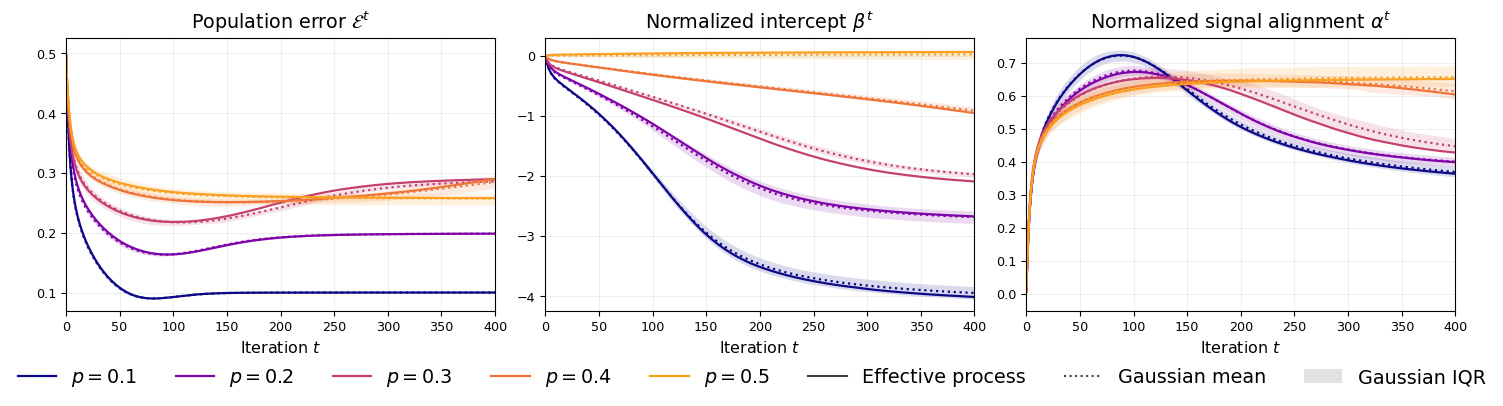

In [60]:
fig_effective, axes_effective = plot_class_imbalance_effective_trajectories(
    histories, effective_results, proportions,
)
save_figure(fig_effective, comparison_dir / "class_imbalance_effective_trajectories.pdf", pad_inches=0.1)

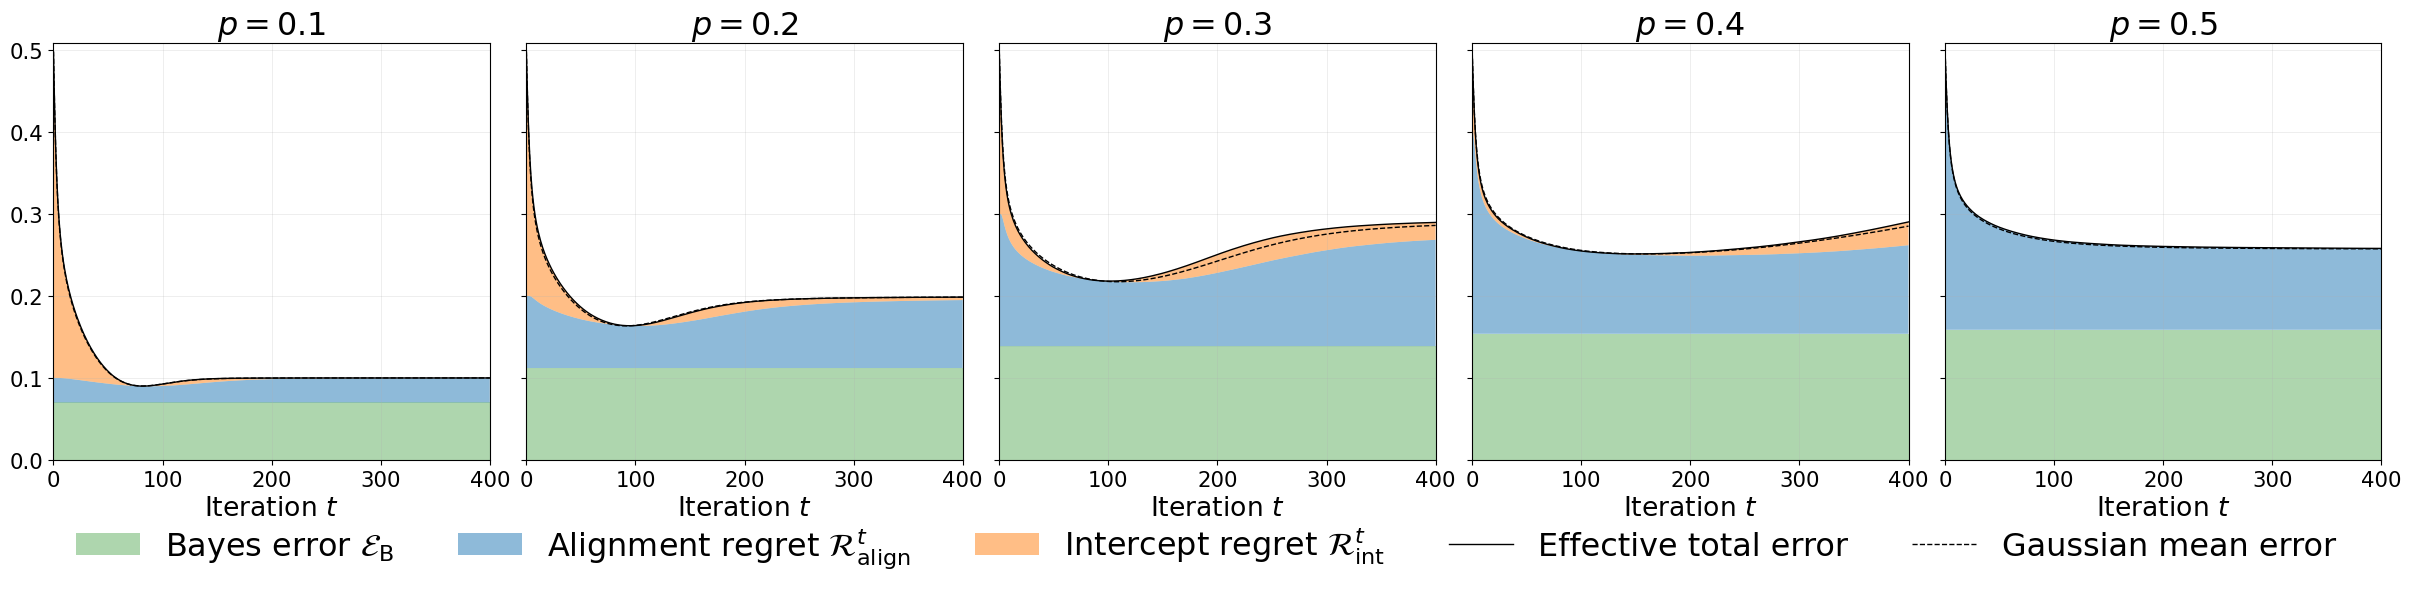

In [61]:
fig_effective_decomposition, axes_effective_decomposition = plot_class_imbalance_decomposition(
    histories, proportions, effective_results=effective_results,
)
save_figure(
    fig_effective_decomposition, comparison_dir / "class_imbalance_effective_decomposition.pdf",
    pad_inches=0.1,
)